# AgroConecta IA: pipeline RAG com LLM local

**Tarefa da IA:** responder dúvidas de pequenos produtores rurais sobre **energia** (geração solar, desconto de irrigação, Luz para Todos, Pronaf, biodigestor, bombeamento) e **mobilidade/escoamento da produção** (pós-colheita, transporte, PNAE, PAA, cadeia do leite), **citando a fonte oficial** e respondendo **"não consta"** quando a base não cobre a pergunta.

Roteiro do notebook:
1. Base de conhecimento e conjunto de teste
2. Busca vetorial: Recall@1 e Recall@3 (dois modelos de embeddings)
3. Escolha do limiar de recusa (conjunto de calibração separado)
4. As três configurações: LLM sem contexto, RAG simples e Agente RAG
5. Placar e interpretação
6. Demonstração de alucinações
7. Erros reais do agente
8. LGPD: mascaramento de dados pessoais

In [1]:
import sys, json, re, unicodedata, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from agroconecta import rag

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
print("LLM:", rag.LLM_MODEL, "| Ollama no ar:", rag.ollama_disponivel())

LLM: llama3.2:1b | Ollama no ar: True


## 1. Base de conhecimento e conjunto de teste

In [2]:
base = rag.carregar_base()
df_base = pd.DataFrame(base)
print(f"{len(base)} trechos")
display(df_base.groupby(["tema", "fonte"]).size().rename("trechos").reset_index())

25 trechos


,tema,fonte,trechos
0,energia,ANEEL – Resolução Normativa nº 1.000/2021; CNA – Alteração no desconto da tarifa de energia elétrica para irrigação,1
1,energia,CNA Brasil – Sistema Famato informa novas regras para desconto na tarifa de energia elétrica para irrigação e aquicu...,1
2,energia,"Decreto nº 11.628, de 4 de agosto de 2023 (Programa Luz para Todos)",1
3,energia,"Decreto nº 12.964, de 8 de maio de 2026 (altera o Decreto 11.628/2023)",1
4,energia,Embrapa Agroenergia – Documentos 55: Biodigestor para pequenos estabelecimentos agropecuários (2024),2
5,energia,Embrapa Clima Temperado – Documentos 443 (Reisser Júnior): energia fotovoltaica na propriedade rural familiar,1
6,energia,Embrapa Instrumentação – Documentos 58: Irrigador solar (2016),1
7,energia,Folha de Pernambuco – Irrigantes de Pernambuco ganham mais liberdade para usar energia com desconto,1
8,energia,"Lei nº 14.300, de 6 de janeiro de 2022 (art. 27 – regra de transição)",1
9,energia,"Lei nº 14.300, de 6 de janeiro de 2022 (marco legal da geração distribuída)",2


In [3]:
testes = json.load(open(RAIZ / "avaliacao" / "testes.json", encoding="utf-8"))
calib = json.load(open(RAIZ / "avaliacao" / "calibracao.json", encoding="utf-8"))
df_t = pd.DataFrame(testes)
print("Teste:", df_t.tipo.value_counts().to_dict(), "| Calibração:", pd.DataFrame(calib).tipo.value_counts().to_dict())
display(df_t[["id", "tipo", "pergunta", "resposta_esperada", "id_documento_correto"]])

Teste: {'respondivel': 28, 'nao_consta': 10} | Calibração: {'respondivel': 9, 'nao_consta': 6}


,id,tipo,pergunta,resposta_esperada,id_documento_correto
0,T01,respondivel,Até quantos kW um sistema solar é considerado microgeração?,Até 75 kW.,1.0
1,T02,respondivel,Por quanto tempo valem os créditos da energia solar que eu jogo na rede?,60 meses (5 anos).,2.0
2,T03,respondivel,Por que um sistema solar instalado agora economiza menos que um antigo?,Por causa da cobrança gradual do Fio B (TUSD) criada pela regra de transição da Lei 14.300.,3.0
3,T04,respondivel,Existe desconto na conta de luz para quem irriga a lavoura?,"Sim, desconto tarifário para irrigação e aquicultura em período diário de 8h30 com horário definido com a distribuid...",4.0
4,T05,respondivel,Quanto de desconto o irrigante de baixa tensão tem em Pernambuco?,73% para o Grupo B (baixa tensão).,5.0
5,T06,respondivel,Qual o percentual de desconto para irrigante do Grupo A na área da SUDENE?,90%.,5.0
6,T07,respondivel,Que documentos preciso apresentar para ganhar o desconto da irrigação?,"Licença ambiental e outorga de uso de recursos hídricos, quando exigidas, e formalizar o horário com a distribuidora.",6.0
7,T08,respondivel,Posso dividir o horário do desconto de irrigação em vários períodos no dia?,"Sim, pode ser contínuo ou fracionado, respeitando o horário de ponta (17h às 21h30).",7.0
8,T09,respondivel,Em que horário o desconto da irrigação não vale?,"No horário de ponta, entre 17h e 21h30.",7.0
9,T10,respondivel,Minha família mora na roça e não tem energia elétrica. Existe algum programa do governo?,"Sim, o Programa Luz para Todos.",8.0


## 2. Busca vetorial: Recall@1 e Recall@3

Comparamos o modelo original do projeto (`all-MiniLM-L6-v2`, treinado em inglês) com dois modelos **multilíngues**: `paraphrase-multilingual-MiniLM-L12-v2` e `intfloat/multilingual-e5-small` (este usa os prefixos `query:`/`passage:`). Os embeddings são normalizados, então o produto interno é a similaridade do cosseno. O recall é medido nas 28 perguntas respondíveis do teste.

In [4]:
def recall(buscador, casos):
    validos = [c for c in casos if c["id_documento_correto"] is not None]
    r1 = r3 = 0
    for c in validos:
        ids = [d["id"] for d in buscador.buscar(c["pergunta"], k=3)]
        r1 += ids[0] == c["id_documento_correto"]
        r3 += c["id_documento_correto"] in ids
    return r1 / len(validos), r3 / len(validos)

buscadores = {m: rag.Buscador(base, modelo=m) for m in ["all-MiniLM-L6-v2", "paraphrase-multilingual-MiniLM-L12-v2", "intfloat/multilingual-e5-small"]}
linhas = []
for nome, b in buscadores.items():
    r1, r3 = recall(b, testes)
    linhas.append({"modelo de embeddings": nome, "Recall@1": f"{r1:.1%}", "Recall@3": f"{r3:.1%}"})
df_recall = pd.DataFrame(linhas)
df_recall.to_csv(RAIZ / "avaliacao" / "recall.csv", index=False, encoding="utf-8-sig")
display(df_recall)
buscador = buscadores[rag.EMB_MODEL]
print("Modelo usado no restante do pipeline:", rag.EMB_MODEL)

D:\gsultimosemestreultimoanorenato\agroconecta-ia-v4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8408.69it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3647.59it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7079.26it/s]

,modelo de embeddings,Recall@1,Recall@3
0,all-MiniLM-L6-v2,71.4%,92.9%
1,paraphrase-multilingual-MiniLM-L12-v2,71.4%,96.4%
2,intfloat/multilingual-e5-small,96.4%,100.0%


Modelo usado no restante do pipeline: intfloat/multilingual-e5-small


In [5]:
# Onde o top-1 erra (modelo escolhido)
for c in testes:
    if c["id_documento_correto"] is None:
        continue
    top = buscador.buscar(c["pergunta"], k=3)
    if top[0]["id"] != c["id_documento_correto"]:
        print(f"{c['id']}: esperado {c['id_documento_correto']}, top-3 = {[(d['id'], round(d['score'], 2)) for d in top]} | {c['pergunta']}")

T23: esperado 21, top-3 = [(20, 0.86), (21, 0.85), (22, 0.83)] | Preciso participar de licitação para vender para a merenda escolar?


## 3. Limiar de recusa

O agente recusa ("não consta") sem chamar a LLM quando o melhor trecho tem similaridade abaixo do limiar. O limiar foi escolhido no **conjunto de calibração** (15 perguntas que não estão no teste), para não ajustar o valor olhando para o teste. Para cada limiar candidato, medimos a acurácia da decisão responder/recusar.

In [6]:
def score_top1(b, casos):
    return [(c["tipo"], b.buscar(c["pergunta"], k=1)[0]["score"]) for c in casos]

sc_cal = score_top1(buscador, calib)
# o E5 concentra os scores numa faixa estreita, então varremos em passos de 0,005 dentro dela
todos = [s for _, s in sc_cal]
linhas = []
for lim in np.arange(round(min(todos), 2) - 0.01, max(todos) + 0.01, 0.005):
    ok = sum((t == "respondivel") == (s >= lim) for t, s in sc_cal)
    resp_ok = sum(t == "respondivel" and s >= lim for t, s in sc_cal)
    rec_ok = sum(t == "nao_consta" and s < lim for t, s in sc_cal)
    linhas.append({"limiar": round(lim, 3), "acurácia decisão": ok / len(sc_cal),
                   "respondíveis liberadas": resp_ok, "fora do escopo barradas": rec_ok})
df_lim = pd.DataFrame(linhas)
df_lim.to_csv(RAIZ / "avaliacao" / "limiar.csv", index=False, encoding="utf-8-sig")
display(df_lim)

print("Scores na calibração:")
for tipo in ["respondivel", "nao_consta"]:
    v = sorted(round(s, 3) for t, s in sc_cal if t == tipo)
    print(f"  {tipo:12s}", v)

,limiar,acurácia decisão,respondíveis liberadas,fora do escopo barradas
0,0.800,0.600000,9,0
1,0.805,0.600000,9,0
2,0.810,0.600000,9,0
3,0.815,0.800000,9,3
4,0.820,0.866667,9,4
5,0.825,1.000000,9,6
6,0.830,1.000000,9,6
7,0.835,0.933333,8,6
8,0.840,0.933333,8,6
9,0.845,0.933333,8,6


Scores na calibração:
  respondivel  [0.831, 0.851, 0.853, 0.878, 0.879, 0.906, 0.909, 0.911, 0.917]
  nao_consta   [0.814, 0.814, 0.815, 0.817, 0.82, 0.824]


In [7]:
melhor = df_lim["acurácia decisão"].max()
# entre os empatados, o MENOR limiar: prefere deixar a LLM decidir a recusar uma pergunta válida
LIMIAR = float(df_lim[df_lim["acurácia decisão"] == melhor]["limiar"].min())
print(f"Limiar escolhido: {LIMIAR} (acurácia de decisão na calibração = {melhor:.0%})")

sc_teste = score_top1(buscador, testes)
ok = sum((t == "respondivel") == (s >= LIMIAR) for t, s in sc_teste)
print(f"Mesmo limiar aplicado ao TESTE: acurácia de decisão = {ok/len(sc_teste):.0%}")
for (t, s), c in zip(sc_teste, testes):
    if (t == "respondivel") != (s >= LIMIAR):
        print(f"  decisão errada: {c['id']} ({t}, score {s:.2f}) {c['pergunta']}")

Limiar escolhido: 0.825 (acurácia de decisão na calibração = 100%)


Mesmo limiar aplicado ao TESTE: acurácia de decisão = 82%
  decisão errada: N02 (nao_consta, score 0.84) Quanto custa um kit de painel solar de 5 kW hoje?
  decisão errada: N03 (nao_consta, score 0.89) Qual a taxa de juros do Pronaf Bioeconomia neste ano?
  decisão errada: N04 (nao_consta, score 0.83) Qual o preço do litro do diesel para o frete da minha safra?
  decisão errada: N05 (nao_consta, score 0.83) Vai chover na semana que vem na minha cidade?
  decisão errada: N07 (nao_consta, score 0.88) Quantos quilos de tomate cabem numa caixa K?
  decisão errada: N08 (nao_consta, score 0.86) Qual o valor do kWh da tarifa rural da minha distribuidora?
  decisão errada: N10 (nao_consta, score 0.87) Quanto biogás por dia produz um biodigestor com 10 vacas?


## 4. As três configurações

| Config | O que é |
|---|---|
| **A. LLM sem contexto** | `llama3.2:1b` respondendo só com o próprio conhecimento (baseline puro) |
| **B. RAG simples** | sempre injeta o trecho top-1 no prompt e pede "não consta" se não souber; sem limiar, sem JSON, sem citação |
| **C. Agente RAG** (especialização) | ciclo *buscar → gerar → verificar*: mascara dados pessoais, **porteiro** por limiar, gera JSON trecho a trecho (até 3 candidatos), **verificador de fundamentação** (todo número e a maior parte das palavras da resposta precisam estar no trecho); reprovou → próximo trecho; nenhum aprovado → "não consta". A fonte é anexada pelo código a partir do trecho aprovado |

As três usam o **mesmo modelo** (`llama3.2:1b`, temperatura 0, seed 42), então a diferença vem só do contexto e do controle.

**Como corrigimos:** a resposta de uma pergunta respondível é **correta** se contém as palavras-chave do gabarito; **recusa indevida** se disse "não consta"; senão é **incorreta (alucinação)**. Numa pergunta "não consta", recusar é o acerto e responder qualquer coisa é **alucinação**. Todas as respostas ficam salvas em `avaliacao/respostas.csv` para conferência manual.

In [8]:
def norm(s):
    s = unicodedata.normalize("NFD", str(s).lower())
    return "".join(ch for ch in s if unicodedata.category(ch) != "Mn")

def recusou(resp):
    # mesmo detector do agente: pega "não consta" e recusas com outras palavras
    # ("Desculpe, mas não tenho acesso...", "Não encontrei informações...")
    return rag.eh_recusa(resp) or norm(resp).strip() in {"", "nao sei"}

def contem(resp, chave):
    r, k = norm(resp), norm(chave)
    if k.isdigit():
        return re.search(rf"(?<!\d){k}(?!\d)", r) is not None
    return k in r

def classificar(caso, resp):
    if caso["tipo"] == "nao_consta":
        return "recusa correta" if recusou(resp) else "alucinação"
    if recusou(resp):
        return "recusa indevida"
    ok = all(any(contem(resp, alt) for alt in grupo) for grupo in caso["palavras_chave"])
    return "correta" if ok else "incorreta (alucinação)"

CONFIGS = {
    "A. LLM sem contexto": lambda p: rag.config_sem_contexto(p),
    "B. RAG simples": lambda p: rag.config_rag_simples(p, buscador),
    "C. Agente RAG": lambda p: rag.config_agente(p, buscador, limiar=LIMIAR),
}

registros = []
t0 = time.time()
for nome, fn in CONFIGS.items():
    for c in testes:
        r = fn(c["pergunta"])
        registros.append({
            "config": nome, "id": c["id"], "tipo": c["tipo"], "pergunta": c["pergunta"],
            "esperado": c["resposta_esperada"], "resposta": r.resposta,
            "id_trecho": r.id_trecho, "id_correto": c["id_documento_correto"],
            "fonte": r.fonte, "json_valido": r.json_valido, "tentativas": r.tentativas,
            "classe": classificar(c, r.resposta), "motivo": r.motivo,
        })
df_r = pd.DataFrame(registros)
df_r.to_csv(RAIZ / "avaliacao" / "respostas.csv", index=False, encoding="utf-8-sig")
print(f"{len(df_r)} respostas geradas em {time.time()-t0:.0f}s")

114 respostas geradas em 306s


## 5. Placar

In [9]:
def placar(g):
    n = len(g)
    resp = g[g.tipo == "respondivel"]
    nc = g[g.tipo == "nao_consta"]
    acertos = (g.classe.isin(["correta", "recusa correta"])).sum()
    aluc = (g.classe.isin(["incorreta (alucinação)", "alucinação"])).sum()
    respondidas = resp[resp.classe != "recusa indevida"]
    cit = (respondidas.id_trecho == respondidas.id_correto).mean() if g.fonte.notna().any() else np.nan
    return pd.Series({
        "acurácia geral": acertos / n,
        "acerto nas respondíveis": (resp.classe == "correta").mean(),
        "recusa correta (não consta)": (nc.classe == "recusa correta").mean(),
        "taxa de alucinação": aluc / n,
        "recusa indevida": (resp.classe == "recusa indevida").mean(),
        "JSON válido": g.json_valido.mean() if g.json_valido.notna().any() else np.nan,
        "citação correta": cit,
    })

df_placar = df_r.groupby("config").apply(placar)
df_placar.to_csv(RAIZ / "avaliacao" / "placar.csv", encoding="utf-8-sig", float_format="%.3f")
display(df_placar.style.format("{:.0%}", na_rep="n/a"))
display(pd.crosstab(df_r.config, df_r.classe))

,acurácia geral,acerto nas respondíveis,recusa correta (não consta),taxa de alucinação,recusa indevida,JSON válido,citação correta
config,,,,,,,
A. LLM sem contexto,24%,18%,40%,71%,7%,n/a,n/a
B. RAG simples,58%,46%,90%,13%,39%,n/a,n/a
C. Agente RAG,87%,82%,100%,11%,4%,100%,93%


classe,alucinação,correta,incorreta (alucinação),recusa correta,recusa indevida
config,,,,,
A. LLM sem contexto,6,5,21,4,2
B. RAG simples,1,13,4,9,11
C. Agente RAG,0,23,4,10,1


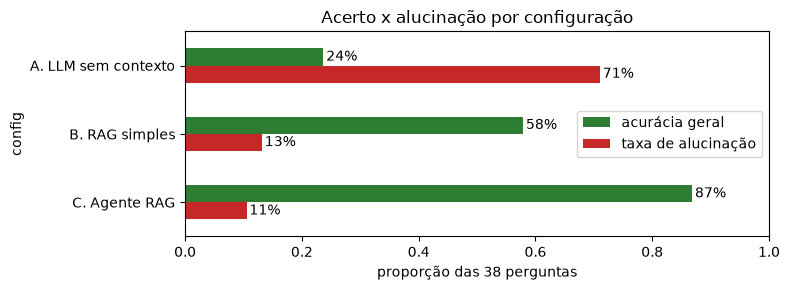

In [10]:
import matplotlib.pyplot as plt
ax = df_placar[["acurácia geral", "taxa de alucinação"]].plot.barh(figsize=(8, 3), color=["#2e7d32", "#c62828"])
ax.set_xlim(0, 1); ax.set_xlabel("proporção das 38 perguntas"); ax.invert_yaxis()
ax.set_title("Acerto x alucinação por configuração")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", labels=[f"{v*100:.0f}%" for v in c.datavalues], padding=2)
plt.tight_layout(); plt.savefig(RAIZ / "avaliacao" / "placar.png", dpi=120); plt.show()

## 6. Demonstração de alucinações

Mesma pergunta, três configurações. Abaixo, as perguntas em que a LLM **sem contexto** alucinou, lado a lado com as respostas do RAG simples e do agente.

In [11]:
piv = df_r.pivot(index="id", columns="config", values="resposta")
cls = df_r.pivot(index="id", columns="config", values="classe")
aluc = cls[cls["A. LLM sem contexto"].str.contains("alucina")]
# primeiro as alucinações factuais (perguntas respondíveis), depois as fora do escopo
aluc_ids = sorted(aluc.index, key=lambda i: (not i.startswith("T"), i))
print(f"A LLM sem contexto alucinou em {len(aluc)} de {len(cls)} perguntas. Exemplos:\n")
for i in aluc_ids[:10]:
    c = next(t for t in testes if t["id"] == i)
    print(f"=== {i} | {c['pergunta']}\n    gabarito: {c['resposta_esperada']}")
    for cfg in CONFIGS:
        print(f"  [{cls.loc[i, cfg]:>22}] {cfg}: {str(piv.loc[i, cfg])[:220]}")
    print()

A LLM sem contexto alucinou em 27 de 38 perguntas. Exemplos:

=== T01 | Até quantos kW um sistema solar é considerado microgeração?
    gabarito: Até 75 kW.
  [incorreta (alucinação)] A. LLM sem contexto: Um sistema solar é considerado microgeração se for capaz de gerar mais de 1 kW.
  [               correta] B. RAG simples: Até 75 kW.
  [               correta] C. Agente RAG: Até 75 kW um sistema solar é considerado microgeração.

=== T03 | Por que um sistema solar instalado agora economiza menos que um antigo?
    gabarito: Por causa da cobrança gradual do Fio B (TUSD) criada pela regra de transição da Lei 14.300.
  [incorreta (alucinação)] A. LLM sem contexto: O sistema solar instalado agora é mais eficiente do que o antigo devido à melhoria na tecnologia e na designação dos componentes. Além disso, a instalação moderna permite a utilização de materiais mais resistentes e durá
  [               correta] B. RAG simples: O sistema solar instalado agora economiza menos do que o antigo

## 7. Erros reais do agente (config C) e do RAG simples (config B)

In [12]:
erros = df_r[(df_r.config != "A. LLM sem contexto") & (~df_r.classe.isin(["correta", "recusa correta"]))]
erros[["config", "id", "classe", "pergunta", "esperado", "resposta", "id_trecho", "id_correto", "motivo"]] \
    .to_csv(RAIZ / "avaliacao" / "erros.csv", index=False, encoding="utf-8-sig")
display(erros[["config", "id", "classe", "pergunta", "esperado", "resposta", "id_trecho", "id_correto", "motivo"]])

,config,id,classe,pergunta,esperado,resposta,id_trecho,id_correto,motivo
39,B. RAG simples,T02,recusa indevida,Por quanto tempo valem os créditos da energia solar que eu jogo na rede?,60 meses (5 anos).,Não consta.,2.0,2.0,
41,B. RAG simples,T04,recusa indevida,Existe desconto na conta de luz para quem irriga a lavoura?,"Sim, desconto tarifário para irrigação e aquicultura em período diário de 8h30 com horário definido com a distribuid...",Não consta.,4.0,4.0,
45,B. RAG simples,T08,recusa indevida,Posso dividir o horário do desconto de irrigação em vários períodos no dia?,"Sim, pode ser contínuo ou fracionado, respeitando o horário de ponta (17h às 21h30).",Não consta.,7.0,7.0,
46,B. RAG simples,T09,recusa indevida,Em que horário o desconto da irrigação não vale?,"No horário de ponta, entre 17h e 21h30.",Não consta,7.0,7.0,
47,B. RAG simples,T10,recusa indevida,Minha família mora na roça e não tem energia elétrica. Existe algum programa do governo?,"Sim, o Programa Luz para Todos.",Não consta.,8.0,8.0,
49,B. RAG simples,T12,recusa indevida,Tem linha de crédito para agricultor familiar comprar painel solar?,"Sim, o Pronaf Bioeconomia financia tecnologias de energia renovável.",Não consta.,10.0,10.0,
51,B. RAG simples,T14,incorreta (alucinação),Dá para usar esterco das vacas para fazer gás de cozinha?,"Sim, com um biodigestor, que transforma dejetos em biogás e substitui o GLP.","Não, não é recomendável usar esterco das vacas para fazer gás de cozinha.",12.0,12.0,
53,B. RAG simples,T16,recusa indevida,Biodigestor serve só para fazenda grande ou para quem tem poucos porcos também?,"Serve também para poucos animais, de pequenas até grandes propriedades.",Não consta,13.0,13.0,
54,B. RAG simples,T17,incorreta (alucinação),Que tipo de bomba é indicada para bombear água com energia solar?,Bombas de pistão e de diafragma.,De pistão.,14.0,14.0,
55,B. RAG simples,T18,incorreta (alucinação),Como funciona o irrigador solar da Embrapa que não usa energia elétrica?,Gotejador com garrafa PET com água e uma bexiga preta aquecida pelo sol.,"O irrigador solar da Embrapa é um gotejador automático feito com material reciclável, que funciona com a água do res...",15.0,15.0,


## 8. LGPD: minimização de dados pessoais

Tudo roda localmente (embeddings e LLM): a pergunta não sai da máquina. Além disso, o agente mascara CPF, e-mail, telefone e CEP e **descarta as frases que só carregam dado pessoal** antes da busca e da LLM (princípio da necessidade, LGPD art. 6º, III). A API não grava as perguntas; o log registra só os *tipos* de dado encontrados.

In [13]:
exemplo = "Meu CPF é 123.456.789-09 e meu telefone (61) 99876-5432. Tem desconto de energia para irrigação?"
mascarado, tipos = rag.mascarar_pii(exemplo)
minimo, _ = rag.minimizar(exemplo)
print("entrada        :", exemplo)
print("mascarado (log):", mascarado, "| tipos:", tipos)
print("enviado à LLM  :", minimo)
print("resposta :", rag.config_agente(exemplo, buscador, limiar=LIMIAR).to_dict())

entrada        : Meu CPF é 123.456.789-09 e meu telefone (61) 99876-5432. Tem desconto de energia para irrigação?
mascarado (log): Meu CPF é [CPF] e meu telefone [TELEFONE]. Tem desconto de energia para irrigação? | tipos: ['CPF', 'TELEFONE']
enviado à LLM  : Tem desconto de energia para irrigação?


resposta : {'resposta': 'O desconto de energia para irrigação é previsto na Resolução Normativa ANEEL nº 1.000/2021, que estabelece que o desconto vale para a energia consumida em um período diário de 8 horas e 30 minutos, em horário noturno definido com a distribuidora.', 'fonte': 'ANEEL – Resolução Normativa nº 1.000/2021; CNA – Alteração no desconto da tarifa de energia elétrica para irrigação', 'url': 'https://cnabrasil.org.br/publicacoes/alteracao-no-desconto-da-tarifa-de-energia-eletrica-para-irrigacao-na-area-atendida-pela-sudene', 'id_trecho': 4, 'score': 0.9164098501205444, 'json_valido': True, 'tentativas': 1, 'motivo': 'trecho 4: aprovado (cobertura 89%)'}
